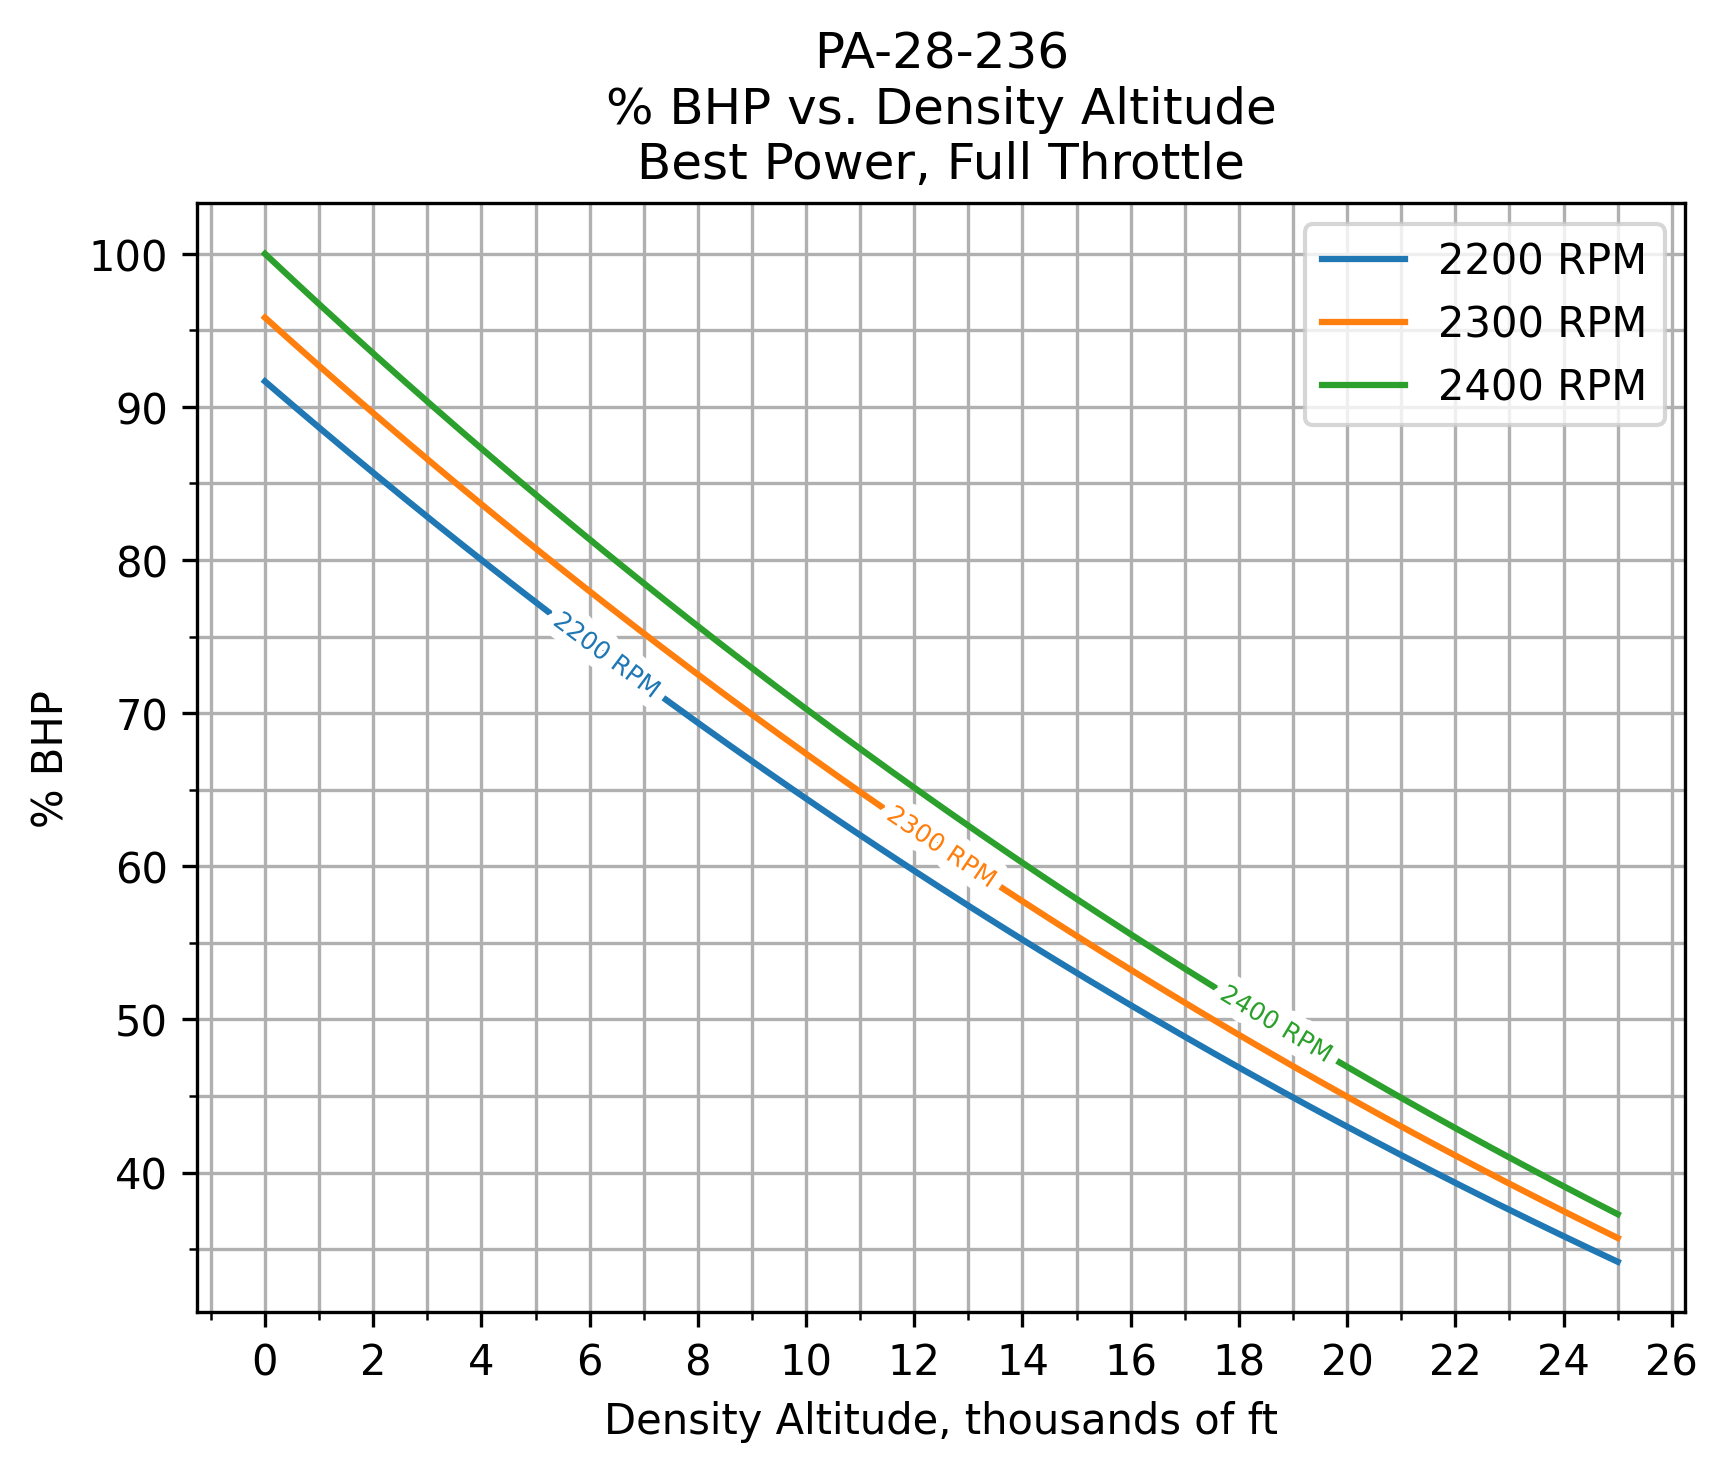

In [9]:
%reload_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
from labellines import labelLines
from matplotlib.ticker import AutoMinorLocator, FuncFormatter, MultipleLocator

from n51sw_dataplate import N51SW
from the_bootstrap_approach.conditions import FullThrottleConditions
from the_bootstrap_approach.equations import *
from the_bootstrap_approach.mixture import Mixture

# Aircraft weight isn't a factor in power output, so set to max gross.
gross_aircraft_weight = 3000
mixture = Mixture.BEST_POWER
pressure_altitude = np.linspace(0, 25000, 1000)

pbhp_2200 = []
pbhp_2300 = []
pbhp_2400 = []

for i in pressure_altitude:
    operating_conditions_at_2200 = FullThrottleConditions(
        N51SW,
        gross_aircraft_weight,
        i,
        british_standard_temperature(i),
        mixture,
        2200,
    )

    operating_conditions_at_2300 = FullThrottleConditions(
        N51SW,
        gross_aircraft_weight,
        i,
        british_standard_temperature(i),
        mixture,
        2300,
    )

    operating_conditions_at_2400 = FullThrottleConditions(
        N51SW,
        gross_aircraft_weight,
        i,
        british_standard_temperature(i),
        mixture,
        2400,
    )

    pbhp_2200.append(
        (operating_conditions_at_2200.power / N51SW.rated_full_throttle_engine_power)
        * 100
    )
    pbhp_2300.append(
        (operating_conditions_at_2300.power / N51SW.rated_full_throttle_engine_power)
        * 100
    )
    pbhp_2400.append(
        (operating_conditions_at_2400.power / N51SW.rated_full_throttle_engine_power)
        * 100
    )

fig, ax = plt.subplots()

ax.plot(pressure_altitude, pbhp_2200, label=r"2200 RPM")
ax.plot(pressure_altitude, pbhp_2300, label=r"2300 RPM")
ax.plot(pressure_altitude, pbhp_2400, label=r"2400 RPM")

labelLines(plt.gca().get_lines(), zorder=2.5, fontsize=6)

ax.set(
    xlabel="Density Altitude, thousands of ft",
    ylabel="% BHP",
    title=(
        "PA-28-236\n"
        "% BHP vs. Density Altitude\n"
        f"{mixture.value}, "
        f"Full Throttle"
    ),
)

ax.grid(True, which="both")

ax.xaxis.set_major_locator(MultipleLocator(2000))
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: "{:,.0f}".format(x / 1000)))
ax.xaxis.set_minor_locator(AutoMinorLocator(2))

ax.yaxis.set_major_locator(MultipleLocator(10))
ax.yaxis.set_minor_locator(AutoMinorLocator(2))

plt.legend()

fig.set(dpi=300)
plt.show()